In [3]:
import pandas as pd
import numpy as np

In [5]:
df=pd.read_csv("netflix_customer_churn_dataset.csv")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [6]:

print("Number OF Rows",df.shape[0])
print("Number OF Columns",df.shape[1])

Number OF Rows 5000
Number OF Columns 14


In [27]:
print(df.head())


                            customer_id  age  gender subscription_type  \
0  a9b75100-82a8-427a-a208-72f24052884a   51   Other             Basic   
1  49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b   47   Other          Standard   
2  4d71f6ce-fca9-4ff7-8afa-197ac24de14b   27  Female          Standard   
3  d3c72c38-631b-4f9e-8a0e-de103cad1a7d   53   Other           Premium   
4  4e265c34-103a-4dbb-9553-76c9aa47e946   56   Other          Standard   

   watch_hours  last_login_days   region  device  monthly_fee  churned  \
0        14.73               29   Africa      TV         8.99        1   
1         0.70               19   Europe  Mobile        13.99        1   
2        16.32               10     Asia      TV        13.99        0   
3         4.51               12  Oceania      TV        17.99        1   
4         1.89               13   Africa  Mobile        13.99        1   

  payment_method  number_of_profiles  avg_watch_time_per_day favorite_genre  
0      Gift Card                

In [15]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'monthly_fee', 'churned', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre']


In [17]:
print("Unique Customer Ids ", df["customer_id"].nunique())

##• unique() returns an array of the actual unique values themselves.
##• nunique() returns a single integer representing the count of those unique values.

Unique Customer Ids  5000


In [23]:
print("Churn Distribution : ",df["churned"].value_counts().sort_index())

Churn Distribution :  churned
0    2485
1    2515
Name: count, dtype: int64


In [24]:
print("Daily Watch Time above 24 hours:  ",(df["avg_watch_time_per_day"]>24).sum())

Daily Watch Time above 24 hours:   10


In [28]:
# Flag records with impossible daily viewing time
suspicious_records = df[
    df["avg_watch_time_per_day"] > 24
]

# Display relevant columns
print(
    suspicious_records[
        [
            "customer_id",
            "watch_hours",
            "avg_watch_time_per_day",
            "last_login_days",
            "churned"
        ]
    ]
)

print("\nNumber of suspicious records:", len(suspicious_records))

                               customer_id  watch_hours  \
647   c350d5a0-fef7-4281-b752-42162d72bd05        25.15   
1219  45ea1095-e06b-4a1c-a0b7-c3671c9f006a        52.80   
2017  23e2a122-9e50-41d8-a434-c25675765f79        98.42   
2564  511d9a10-669b-4283-bc6d-40c10a595b43        34.53   
3641  64d85f24-42f8-48b1-8675-590db42d23e5        28.66   
4078  9adb0b11-3199-438c-9b3c-59dee22c6b27        32.81   
4285  3878e4e3-2960-4b36-b25c-f90ddd01b5d8        54.53   
4792  88a98e69-9e49-4d28-98d7-1e0b1bce6138        32.88   
4805  b906246e-44aa-441f-85c5-fc2aa946b0cb        29.55   
4845  d202349e-dd45-42e7-84a9-fa604082763f        26.98   

      avg_watch_time_per_day  last_login_days  churned  
647                    25.15                0        0  
1219                   52.80                0        0  
2017                   98.42                0        0  
2564                   34.53                0        0  
3641                   28.66                0        0  
4078    

In [29]:

print(df[["watch_hours", "avg_watch_time_per_day"]].describe())

print("\nCorrelation between viewing-time columns:")
print(df[["watch_hours", "avg_watch_time_per_day"]].corr()
)


       watch_hours  avg_watch_time_per_day
count  5000.000000             5000.000000
mean     11.649450                0.874800
std      12.014654                2.619824
min       0.010000                0.000000
25%       3.337500                0.110000
50%       8.000000                0.290000
75%      16.030000                0.720000
max     110.400000               98.420000

Correlation between viewing-time columns:
                        watch_hours  avg_watch_time_per_day
watch_hours                1.000000                0.349742
avg_watch_time_per_day     0.349742                1.000000


In [31]:

# Exclude the customer identifier
categorical_columns = [
    col for col in df.select_dtypes(include="object").columns
    if col != "customer_id"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False))



--- gender ---
Unique values: 3
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

--- subscription_type ---
Unique values: 3
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

--- region ---
Unique values: 6
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

--- device ---
Unique values: 5
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

--- payment_method ---
Unique values: 5
payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

--- favorite_genre ---
Unique values: 7
favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Name: count, dtype: int64


In [32]:

numeric_columns = df.select_dtypes(include="number").columns

print(df[numeric_columns].agg(["min", "max"]).T)


                          min     max
age                     18.00   70.00
watch_hours              0.01  110.40
last_login_days          0.00   60.00
monthly_fee              8.99   17.99
churned                  0.00    1.00
number_of_profiles       1.00    5.00
avg_watch_time_per_day   0.00   98.42


In [34]:

# Compare churn across subscription types

churn_by_subscription = (
    df.groupby("subscription_type")
    .agg(
        total_customers=("customer_id", "count"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

churn_by_subscription["churn_rate_percentage"] = (
    churn_by_subscription["churn_rate"] * 100
).round(2)

churn_by_subscription = churn_by_subscription.drop(
    columns="churn_rate"
)

print(churn_by_subscription)


  subscription_type  total_customers  churned_customers  churn_rate_percentage
0             Basic             1661               1027                  61.83
1           Premium             1693                740                  43.71
2          Standard             1646                748                  45.44


In [49]:

# Compare churn across watch-hour groups

df["watch_group"] = pd.cut(
    df["watch_hours"],
    bins=[-float("inf"), 5, 15, float("inf")],
    labels=[
        "Low (5 hours or less)",
        "Medium (over 5 to 15 hours)",
        "High (over 15 hours)"
    ]
)

watch_analysis = (
    df.groupby("watch_group", observed=False)
      .agg(
          total_customers=("customer_id", "count"),
          churned_customers=("churned", "sum")
      )
)

watch_analysis["churn_rate_pct"] = (
    watch_analysis["churned_customers"]
    / watch_analysis["total_customers"] * 100
).round(2)

display(watch_analysis)
  

,total_customers,churned_customers,churn_rate_pct
watch_group,,,
Low (5 hours or less),1770,1486,83.95
Medium (over 5 to 15 hours),1876,826,44.03
High (over 15 hours),1354,203,14.99


# Hence the customers who view less hours are churned 

In [39]:

# Step 1: Group customers by days since their last login
df["login_group"] = pd.cut(
    df["last_login_days"],
    bins=[-float("inf"), 7, 30, float("inf")],
    labels=["Recent (0-7 days)",
            "Inactive (8-30 days)",
            "Long inactive (over 30 days)"]
)

# Step 2: Count total customers in each group
total_customers = df.groupby(
    "login_group", observed=False
)["customer_id"].count()

# Step 3: Count churned customers in each group
churned_customers = df.groupby(
    "login_group", observed=False
)["churned"].sum()

# Step 4: Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

# Step 5: Combine results into one table
login_analysis = pd.DataFrame({
    "Total Customers": total_customers,
    "Churned Customers": churned_customers,
    "Churn Rate (%)": churn_rate.round(2)
})

# Step 6: Display the results
print(login_analysis.to_string())

                              Total Customers  Churned Customers  Churn Rate (%)
login_group                                                                     
Recent (0-7 days)                         650                 87           13.38
Inactive (8-30 days)                     1881                574           30.52
Long inactive (over 30 days)             2469               1854           75.09


In [40]:

# Compare subscription type and login activity

# Step 1: Group customers by both characteristics
grouped_data = df.groupby(
    ["subscription_type", "login_group"],
    observed=False
)

# Step 2: Count customers in each group
total_customers = grouped_data["customer_id"].count()

# Step 3: Count churned customers in each group
churned_customers = grouped_data["churned"].sum()

# Step 4: Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

# Step 5: Combine everything into one table
combined_analysis = pd.DataFrame({
    "Total Customers": total_customers,
    "Churned Customers": churned_customers,
    "Churn Rate (%)": churn_rate.round(2)
}).reset_index()

# Step 6: Display results
print(combined_analysis.to_string(index=False))




subscription_type                  login_group  Total Customers  Churned Customers  Churn Rate (%)
            Basic            Recent (0-7 days)              214                 57           26.64
            Basic         Inactive (8-30 days)              612                242           39.54
            Basic Long inactive (over 30 days)              835                728           87.19
          Premium            Recent (0-7 days)              217                 16            7.37
          Premium         Inactive (8-30 days)              657                160           24.35
          Premium Long inactive (over 30 days)              819                564           68.86
         Standard            Recent (0-7 days)              219                 14            6.39
         Standard         Inactive (8-30 days)              612                172           28.10
         Standard Long inactive (over 30 days)              815                562           68.96


Each row represents a combination of (subscription type , login activity)

Key insight: Basic customers who have been inactive for over 30 days have the highest observed churn rate: 87.19%.

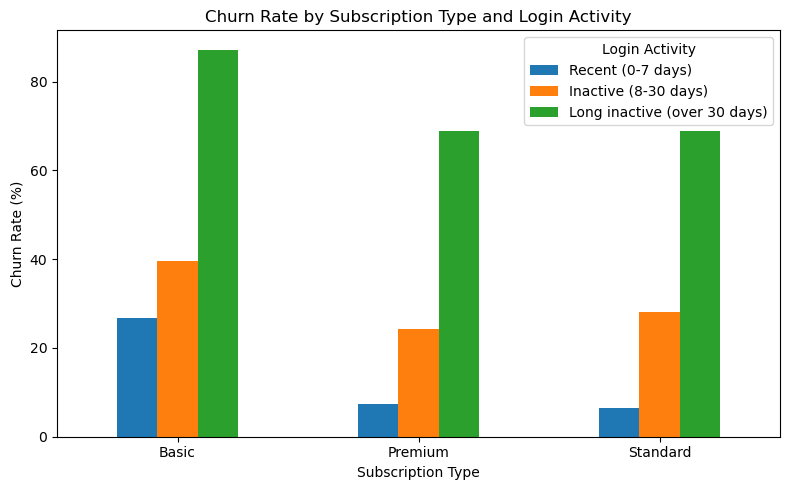

In [56]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate churn rate for each combination
churn_table = df.pivot_table(
    index="subscription_type",
    columns="login_group",
    values="churned",
    aggfunc="mean",
    observed=False
) * 100

# Create a grouped bar chart
churn_table.plot(
    kind="bar",
    figsize=(8,5)
)

# Add chart details
plt.title("Churn Rate by Subscription Type and Login Activity")
plt.xlabel("Subscription Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Login Activity")
plt.tight_layout()
plt.show()


In [57]:

# Monthly-fee exposure by churn status

fee_exposure = (
    df.groupby("churned")
    .agg(
        total_customers=("customer_id", "count"),
        total_monthly_fee=("monthly_fee", "sum"),
        average_monthly_fee=("monthly_fee", "mean")
    )
    .rename(index={0: "Not Churned", 1: "Churned"})
    .round(2)
)

display(fee_exposure)


,total_customers,total_monthly_fee,average_monthly_fee
churned,,,
Not Churned,2485,35407.15,14.25
Churned,2515,33009.85,13.13


In [58]:

# Retention prioritisation by subscription type and login inactivity

retention_priority = (
    df.groupby(
        ["subscription_type", "login_group"],
        observed=False
    )
    .agg(
        total_customers=("customer_id", "count"),
        churned_customers=("churned", "sum"),
        total_monthly_fee=("monthly_fee", "sum")
    )
)

retention_priority["churn_rate_pct"] = (
    retention_priority["churned_customers"]
    / retention_priority["total_customers"] * 100
).round(2)

retention_priority["churned_fee_exposure"] = (
    df.assign(
        churned_fee=df["monthly_fee"] * df["churned"]
    )
    .groupby(["subscription_type", "login_group"], observed=False)
    ["churned_fee"].sum()
)

retention_priority = retention_priority[
    [
        "total_customers",
        "churned_customers",
        "churn_rate_pct",
        "total_monthly_fee",
        "churned_fee_exposure"
    ]
].sort_values(
    ["churn_rate_pct", "churned_customers"],
    ascending=[False, False]
).round(2)

display(retention_priority)


total_customers  \
subscription_type login_group                                     
Basic             Long inactive (over 30 days)              835   
Standard          Long inactive (over 30 days)              815   
Premium           Long inactive (over 30 days)              819   
Basic             Inactive (8-30 days)                      612   
Standard          Inactive (8-30 days)                      612   
Basic             Recent (0-7 days)                         214   
Premium           Inactive (8-30 days)                      657   
                  Recent (0-7 days)                         217   
Standard          Recent (0-7 days)                         219   

                                                churned_customers  \
subscription_type login_group                                       
Basic             Long inactive (over 30 days)                728   
Standard          Long inactive (over 30 days)                562   
Premium           Long inactive (over 30 days)                564   
Basic             Inactive (8-30 days)                        242   
Standard          Inactive (8-30 days)                        172   
Basic             Recent (0-7 days)                            57   
Premium           Inactive (8-30 days)                        160   
                  Recent (0-7 days)                            16   
Standard          Recent (0-7 days)                            14   

                                                churn_rate_pct  \
subscription_type login_group                                    
Basic             Long inactive (over 30 days)           87.19   
Standard          Long inactive (over 30 days)           68.96   
Premium           Long inactive (over 30 days)           68.86   
Basic             Inactive (8-30 days)                   39.54   
Standard          Inactive (8-30 days)                   28.10   
Basic             Recent (0-7 days)                      26.64   
Premium           Inactive (8-30 days)                   24.35   
                  Recent (0-7 days)                       7.37   
Standard          Recent (0-7 days)                       6.39   

                                                total_monthly_fee  \
subscription_type login_group                                       
Basic             Long inactive (over 30 days)            7506.65   
Standard          Long inactive (over 30 days)           11401.85   
Premium           Long inactive (over 30 days)           14733.81   
Basic             Inactive (8-30 days)                    5501.88   
Standard          Inactive (8-30 days)                    8561.88   
Basic             Recent (0-7 days)                       1923.86   
Premium           Inactive (8-30 days)                   11819.43   
                  Recent (0-7 days)                       3903.83   
Standard          Recent (0-7 days)                       3063.81   

                                                churned_fee_exposure  
subscription_type login_group                                         
Basic             Long inactive (over 30 days)               6544.72  
Standard          Long inactive (over 30 days)               7862.38  
Premium           Long inactive (over 30 days)              10146.36  
Basic             Inactive (8-30 days)                       2175.58  
Standard          Inactive (8-30 days)                       2406.28  
Basic             Recent (0-7 days)                           512.43  
Premium           Inactive (8-30 days)                       2878.40  
                  Recent (0-7 days)                           287.84  
Standard          Recent (0-7 days)                           195.86

In [48]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Check the target column
if "churned" not in df.columns:
    raise ValueError("The dataset must contain a 'churned' column.")

data = df.copy()

# Convert the target to numeric and retain valid 0/1 labels
data["churned"] = pd.to_numeric(data["churned"], errors="coerce")
data = data[data["churned"].isin([0, 1])].copy()
data["churned"] = data["churned"].astype(int)

if data["churned"].nunique() != 2:
    raise ValueError("Both churn classes (0 and 1) are required.")

# 2. Select usable customer characteristics
# Exclude identifiers, the target, and previously created analysis groups
excluded_columns = {
    "customer_id", "churned",
    "watch_group", "login_group", "age_group",
    "watch_time_quality_issue"
}

# Exclude columns that directly reveal the churn outcome
leakage_words = [
    "churn", "cancel", "termination",
    "retention_status", "status"
]

feature_columns = [
    col for col in data.columns
    if col not in excluded_columns
    and not any(word in col.lower() for word in leakage_words)
]

# Exclude columns with no useful variation
feature_columns = [
    col for col in feature_columns
    if data[col].nunique(dropna=True) > 1
]

# Exclude date/time fields for this first model
date_columns = [
    col for col in feature_columns
    if (
        pd.api.types.is_datetime64_any_dtype(data[col])
        or "date" in col.lower()
        or col.lower().endswith("_at")
    )
]
feature_columns = [
    col for col in feature_columns if col not in date_columns
]

if not feature_columns:
    raise ValueError("No suitable predictor columns were found.")

X = data[feature_columns].copy()
y = data["churned"]

# 3. Separate numerical and categorical columns
numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = [
    col for col in X.columns if col not in numeric_columns
]

# 4. Prepare the data
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# 5. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 6. Train the logistic regression model
model = Pipeline([
    ("preparation", preprocessor),
    ("logistic_regression", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

# 7. Evaluate the model on unseen test data
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("MULTIVARIABLE CHURN ANALYSIS")
print("=" * 35)
print("Rows analysed:", len(data))
print("Predictor columns used:", feature_columns)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Precision:", round(precision_score(
    y_test, predictions, zero_division=0
), 3))
print("Recall:", round(recall_score(
    y_test, predictions, zero_division=0
), 3))
print("F1 score:", round(f1_score(
    y_test, predictions, zero_division=0
), 3))
print("ROC-AUC:", round(roc_auc_score(
    y_test, probabilities
), 3))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, predictions, zero_division=0
))


MULTIVARIABLE CHURN ANALYSIS
Rows analysed: 5000
Predictor columns used: ['age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'monthly_fee', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre']
Training records: 4000
Testing records: 1000

MODEL PERFORMANCE
Accuracy: 0.887
Precision: 0.875
Recall: 0.905
F1 score: 0.89
ROC-AUC: 0.966

CONFUSION MATRIX
[[432  65]
 [ 48 455]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       497
           1       0.88      0.90      0.89       503

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000

